# 04 — Baseline models

**Goal.** Build the reference models of Deliverable 1 and tune the logistic regression, using
**hospital A only**:
- the **training** patients (A-train) to fit and tune the models,
- the **calibration** patients (A-calib) to check and correct the predicted probabilities,
  and to compare the models.

The test sets (A-test and all of hospital B) are **not touched here**: they are used once, in
notebook 05, for the final evaluation.

**Models.**
1. Majority class — always predicts the average risk (shows why accuracy is useless here).
2. qSOFA-style rule — a simple clinical score, no learning.
3. L2-regularised logistic regression — our baseline model.

**Inputs.** `data/processed/features_baseline.pkl`, `data/processed/patients_splits.csv`
(notebook 02) and `notebooks/sepsis_utils.py` (small shared helpers).

**Output.** `data/processed/baseline_logistic.joblib` (the fitted model, read by notebook 05)
and figures in `report/figures/`.

## 0. Setup

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sepsis_utils import (QuantileClipper, expected_calibration_error, logit, qsofa_score,
                          reliability_table)

SEED = 42
PROCESSED = Path("../data/processed")
FIG = Path("../report/figures")
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 4)

features = pd.read_pickle(PROCESSED / "features_baseline.pkl")
patients = pd.read_csv(PROCESSED / "patients_splits.csv")
features.shape

(1552210, 80)

## 1. Training and calibration sets (hospital A)

In [ ]:
# Attach to each row the split of its patient (decided in notebook 02)
split_of = patients.set_index("patient_id")["split"]
in_A = features["hospital"] == "A"
split = features["patient_id"].map(split_of) #donne à chaque ligne l'ensenmble du patient

train = features[in_A & (split == "train")]
calib = features[in_A & (split == "calib")]

for name, d in [("A-train", train), ("A-calib", calib)]:
    print(f"{name}: {d['patient_id'].nunique()} patients, {len(d)} hours, "
          f"{d['SepsisLabel'].mean():.2%} positive hours")

A-train: 12201 patients, 473006 hours, 2.18% positive hours
A-calib: 4067 patients, 157812 hours, 2.17% positive hours


## 2. Input columns

We start from the 77 columns built in notebook 02 and remove:
- `Unit2` and `Unit2_missing`: exact duplicates of `Unit1` and `Unit1_missing`
  (notebook 03, section 5);
- every column that has a single value in A-train: it carries no information for a model trained
  on A. This removes EtCO2, which is never measured in hospital A (notebook 03, section 3).
  The decision uses the **training patients only**.

In [3]:
ID_COLS = ["patient_id", "hospital", "SepsisLabel"]
candidates = [c for c in features.columns if c not in ID_COLS + ["Unit2", "Unit2_missing"]]
constant_in_train = [c for c in candidates if train[c].nunique(dropna=True) <= 1]
FEATURES = [c for c in candidates if c not in constant_in_train]

print(len(FEATURES), "input columns")
print("removed (single value in A-train):", constant_in_train)

72 input columns
removed (single value in A-train): ['EtCO2', 'EtCO2_missing', 'HospAdmTime_missing']


In [4]:
# X = inputs, y = label (1 = sepsis within 6 hours), groups = patient of each row
X_train, y_train, g_train = train[FEATURES], train["SepsisLabel"].to_numpy(), train["patient_id"].to_numpy()
X_calib, y_calib = calib[FEATURES], calib["SepsisLabel"].to_numpy()

In [5]:
# One function to score every model the same way.
# - AUPRC (main metric) and AUROC: does the model rank septic hours above the others?
# - Brier and ECE (probabilities only): is the predicted risk the real risk?
# - accuracy, sensitivity and alert rate at a threshold: what happens if we raise an alert above it?
def evaluate(y, score, threshold, is_probability=True):
    alert = score >= threshold
    row = {
        "AUPRC": average_precision_score(y, score),
        "AUROC": roc_auc_score(y, score),
        "Brier": brier_score_loss(y, score) if is_probability else np.nan,
        "ECE": expected_calibration_error(y, score) if is_probability else np.nan,
        "accuracy": (alert == y).mean(),
        "sensitivity": alert[y == 1].mean(),
        "alert_rate": alert.mean(),
    }
    return row

## 3. Reference model 1 — majority class

The "model" always predicts the share of positive hours of A-train, whatever the patient.
With a threshold of 0.5 it never raises an alert.

In [6]:
majority = DummyClassifier(strategy="prior").fit(X_train, y_train)
p_majority = majority.predict_proba(X_calib)[:, 1]
pd.Series(evaluate(y_calib, p_majority, threshold=0.5), name="majority class (A-calib)")

AUPRC          2.1728e-02
AUROC          5.0000e-01
Brier          2.1256e-02
ECE            3.2438e-05
accuracy       9.7827e-01
sensitivity    0.0000e+00
alert_rate     0.0000e+00
Name: majority class (A-calib), dtype: float64

## 4. Reference model 2 — qSOFA-style rule

qSOFA is a bedside score used to flag patients at risk of sepsis. We use two of its three criteria,
from the last observed values: respiratory rate ≥ 22 /min and systolic blood pressure ≤ 100 mmHg
(the third, altered mentation, is not in the data). The score is 0, 1 or 2; an alert is raised at 2.
Nothing is learned: it is a fixed rule.

In [7]:
q_calib = qsofa_score(calib)
print(q_calib.value_counts(normalize=True).sort_index().rename("share of hours"))
pd.Series(evaluate(y_calib, q_calib.to_numpy(), threshold=2, is_probability=False), name="qSOFA rule (A-calib)")

0    0.6212
1    0.3366
2    0.0422
Name: share of hours, dtype: float64


AUPRC          0.0248
AUROC          0.5557
Brier             NaN
ECE               NaN
accuracy       0.9385
sensitivity    0.0566
alert_rate     0.0422
Name: qSOFA rule (A-calib), dtype: float64

## 5. Logistic regression — pipeline and tuning

**The Pipeline.** Four steps, always applied in this order:
1. `QuantileClipper` — clips each variable to its 0.5 % and 99.5 % percentiles (the outlier decision
   of notebook 03), indicators excluded;
2. `SimpleImputer(median)` — fills the variables never measured so far with the median;
3. `StandardScaler` — puts every column on the same scale (mean 0, standard deviation 1), which the
   L2 penalty needs;
4. `LogisticRegression` — the model.

The first three steps **learn** something from the data (limits, medians, means). Because they are
inside the Pipeline, they are fitted on the training rows only — and, during cross-validation, on
the training folds only. This is what prevents leakage.

**Tuning.** Two settings are chosen by 5-fold cross-validation on A-train:
- `C`: strength of the L2 penalty (small C = strong penalty = simpler model);
- `class_weight`: `None`, or `"balanced"` (positive hours count about 45 times more in the loss).

The folds are **grouped by patient** (`StratifiedGroupKFold`): all hours of a patient are in the same
fold, otherwise the model would be validated on hours of patients it has already seen. "Stratified"
keeps about the same share of positive hours in each fold. The score is the **AUPRC**.

In [8]:
pipeline = Pipeline([
    ("clip", QuantileClipper(lower=0.5, upper=99.5)),
    ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])

grid = {
    "model__C": [0.001, 0.01, 0.1, 1.0],
    "model__class_weight": [None, "balanced"],
}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(pipeline, grid, scoring="average_precision", cv=cv,
                      n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train, groups=g_train)   # 8 settings x 5 folds = 40 fits, a few minutes
print("tuning done")

tuning done


In [9]:
# Cross-validation results, best setting first.
# train_AUPRC much higher than cv_AUPRC would mean overfitting.
res = search.cv_results_
cv_table = pd.DataFrame({
    "C": [p["model__C"] for p in res["params"]],
    "class_weight": [str(p["model__class_weight"]) for p in res["params"]],
    "cv_AUPRC_mean": res["mean_test_score"],
    "cv_AUPRC_sd": res["std_test_score"],
    "train_AUPRC_mean": res["mean_train_score"],
}).sort_values("cv_AUPRC_mean", ascending=False)
print("best setting:", search.best_params_)
cv_table

best setting: {'model__C': 0.001, 'model__class_weight': None}


,C,class_weight,cv_AUPRC_mean,cv_AUPRC_sd,train_AUPRC_mean
0,0.001,None,0.0929,0.0043,0.1001
2,0.010,None,0.0918,0.0040,0.1006
6,1.000,None,0.0916,0.0040,0.1006
4,0.100,None,0.0916,0.0040,0.1006
1,0.001,balanced,0.0915,0.0031,0.0956
3,0.010,balanced,0.0911,0.0031,0.0955
5,0.100,balanced,0.0911,0.0031,0.0955
7,1.000,balanced,0.0911,0.0031,0.0955


## 6. Calibration — is the predicted risk the real risk?

The best setting is refitted on all of A-train (`search.best_estimator_`). We check its probabilities
on the **calibration patients**, which the model has never seen.

A reliability diagram groups the hours by predicted risk (0–10 %, 10–20 %, …) and compares, in each
group, the average predicted risk with the share of hours that really are septic. A calibrated
model lies on the diagonal.

**Platt scaling** corrects the probabilities with a small logistic regression on the logit of the
raw probability. To judge it honestly, it is fitted on one half of the calibration patients and
checked on the other half, then the other way round. The final correction, used in notebook 05, is
then fitted on all calibration patients.

In [10]:
model = search.best_estimator_
p_raw = model.predict_proba(X_calib)[:, 1]

# Platt scaling, cross-fitted on two halves of the calibration patients
calib_ids = calib["patient_id"].unique()
rng = np.random.default_rng(SEED)
half = rng.choice(calib_ids, size=len(calib_ids) // 2, replace=False)
in_half = calib["patient_id"].isin(half).to_numpy()

p_platt = np.empty_like(p_raw)
for fit_rows, apply_rows in [(in_half, ~in_half), (~in_half, in_half)]:
    m = LogisticRegression(C=np.inf).fit(logit(p_raw[fit_rows]).reshape(-1, 1), y_calib[fit_rows])
    p_platt[apply_rows] = m.predict_proba(logit(p_raw[apply_rows]).reshape(-1, 1))[:, 1]

# Final correction for notebook 05, fitted on all calibration patients
platt = LogisticRegression(C=np.inf).fit(logit(p_raw).reshape(-1, 1), y_calib)

pd.DataFrame({
    "Brier": [brier_score_loss(y_calib, p_raw), brier_score_loss(y_calib, p_platt)],
    "ECE": [expected_calibration_error(y_calib, p_raw), expected_calibration_error(y_calib, p_platt)],
    "mean predicted risk": [p_raw.mean(), p_platt.mean()],
    "observed share of positive hours": [y_calib.mean(), y_calib.mean()],
}, index=["logistic, raw", "logistic + Platt (cross-fitted)"])

,Brier,ECE,mean predicted risk,observed share of positive hours
"logistic, raw",0.0206,0.0014,0.0218,0.0217
logistic + Platt (cross-fitted),0.0207,0.0017,0.0218,0.0217


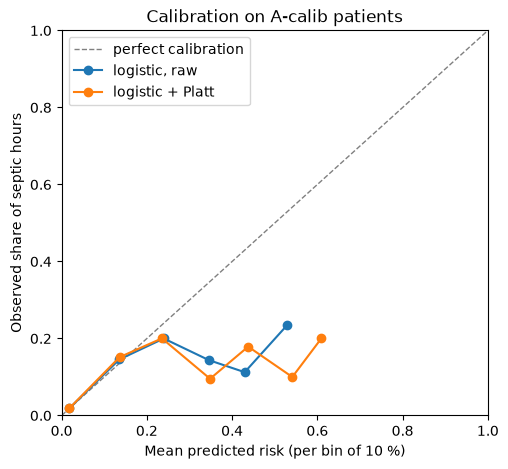

,bin,n_hours,mean_predicted,observed
0,0,154078,0.0180,0.0185
1,1,2746,0.1355,0.1457
2,2,585,0.2397,0.2000
3,3,306,0.3455,0.1438
4,4,80,0.4295,0.1125
5,5,17,0.5296,0.2353


In [11]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1, label="perfect calibration")
for name, p in [("logistic, raw", p_raw), ("logistic + Platt", p_platt)]:
    t = reliability_table(y_calib, p)
    ax.plot(t["mean_predicted"], t["observed"], marker="o", label=name)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean predicted risk (per bin of 10 %)")
ax.set_ylabel("Observed share of septic hours")
ax.set_title("Calibration on A-calib patients")
ax.legend()
fig.savefig(FIG / "baseline_reliability_calib.png", dpi=150, bbox_inches="tight")
plt.show()

# Number of hours behind each point (a point with few hours is not reliable)
reliability_table(y_calib, p_raw)

## 7. Comparison of the three models on A-calib

This is a **validation** comparison, on patients not used for training. The final numbers, with
confidence intervals, come from the test sets in notebook 05.

In [12]:
comparison = pd.DataFrame({
    "majority class": evaluate(y_calib, p_majority, threshold=0.5),
    "qSOFA rule (alert at 2)": evaluate(y_calib, q_calib.to_numpy(), threshold=2, is_probability=False),
    "logistic, raw (alert at 0.5)": evaluate(y_calib, p_raw, threshold=0.5),
    "logistic + Platt (alert at 0.5)": evaluate(y_calib, p_platt, threshold=0.5),
}).T
comparison

,AUPRC,AUROC,Brier,ECE,accuracy,sensitivity,alert_rate
majority class,0.0217,0.5000,0.0213,3.2438e-05,0.9783,0.0000,0.0000
qSOFA rule (alert at 2),0.0248,0.5557,NaN,NaN,0.9385,0.0566,0.0422
"logistic, raw (alert at 0.5)",0.0922,0.7801,0.0206,1.4286e-03,0.9782,0.0012,0.0001
logistic + Platt (alert at 0.5),0.0897,0.7797,0.0207,1.7187e-03,0.9781,0.0012,0.0002


## 8. What the logistic regression learned

The inputs are standardised, so each coefficient is the change in log-odds of sepsis for an increase
of one standard deviation of the variable (positive = higher risk). Two warnings when reading them:
- strongly correlated variables (e.g. MAP, SBP, DBP) share their effect, so their coefficients must
  not be read one by one;
- a `_missing` coefficient is the effect of "never measured so far", compared with a median value.

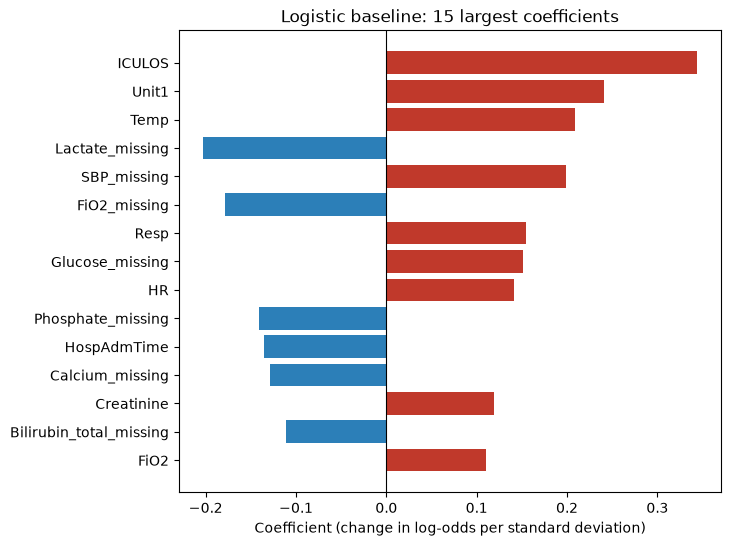

ICULOS                     0.343
Unit1                      0.241
Temp                       0.209
Lactate_missing           -0.202
SBP_missing                0.199
FiO2_missing              -0.178
Resp                       0.155
Glucose_missing            0.151
HR                         0.142
Phosphate_missing         -0.140
HospAdmTime               -0.136
Calcium_missing           -0.129
Creatinine                 0.119
Bilirubin_total_missing   -0.111
FiO2                       0.110
dtype: float64

In [13]:
coefs = pd.Series(model.named_steps["model"].coef_.ravel(), index=FEATURES)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index[::-1], top.values[::-1], color=np.where(top.values[::-1] > 0, "#c0392b", "#2c7fb8"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coefficient (change in log-odds per standard deviation)")
ax.set_title("Logistic baseline: 15 largest coefficients")
fig.savefig(FIG / "baseline_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()
top.round(3)

## 9. Save the model for notebook 05

In [14]:
bundle = {
    "pipeline": model,             # clipping + imputation + scaling + logistic regression, fitted on A-train
    "platt": platt,                # probability correction, fitted on A-calib
    "features": FEATURES,          # input columns, in order
    "best_params": search.best_params_,
    "cv_auprc": search.best_score_,
}
joblib.dump(bundle, PROCESSED / "baseline_logistic.joblib")
print("saved:", PROCESSED / "baseline_logistic.joblib")

saved: ..\data\processed\baseline_logistic.joblib


## 10. Observations

- **Majority class.** 97.8 % accuracy with a sensitivity of 0: it never raises an alert. Its AUROC (0.50)
  and AUPRC (0.022, the share of positive hours) are the "no skill" reference.
- **qSOFA rule.** Barely better than chance: AUROC 0.56 and AUPRC 0.025 (random: 0.022). Alerting at a
  score of 2 flags 4.2 % of the hours but catches only 5.7 % of the septic hours. Two of the three qSOFA
  criteria, read hour by hour, do not anticipate sepsis 6 hours ahead.
- **Tuning.** Best setting: C = 0.001 and class_weight = None (CV AUPRC 0.093 ± 0.004). The 8 settings lie
  between 0.091 and 0.093, within the fold-to-fold variation (SD 0.003–0.004): with 473 000 training hours
  and 72 inputs, the strength of the penalty barely matters. class_weight = "balanced" is slightly worse.
  The train AUPRC (0.100) is close to the CV AUPRC: little overfitting.
  **Change from Deliverable 1**, which planned class weights: cross-validation chose no class weights,
  which also keeps the predicted probabilities calibrated.
- **Calibration.** Without class weights, the raw probabilities are already well calibrated on A-calib:
  mean predicted risk 2.18 % vs 2.17 % observed, ECE 0.0014. The reliability diagram follows the diagonal
  up to about 25 % of predicted risk, which covers 99.7 % of the hours. Above 30 % the model overestimates
  the risk (e.g. 35 % predicted vs 14 % observed), but these bins hold only 403 hours. Platt scaling brings
  no gain here (ECE 0.0017, Brier 0.0207 vs 0.0206, within noise). It is kept for notebook 05: hospital B
  has a lower share of positive hours (1.4 %), so the calibration may degrade there.
- **Comparison.** The logistic regression ranks the hours much better than both references: AUPRC 0.092
  (about 4 times the random level) and AUROC 0.78. In absolute terms the AUPRC stays low: predicting sepsis
  6 hours ahead from routine hourly data is hard. A threshold of 0.5 is meaningless for a model whose
  predicted risks are almost all below 20 %: it raises an alert on 0.01 % of the hours. In notebook 05 the
  alert threshold will be set on A-calib for a target alert rate (e.g. 5 % of the hours), so that the models
  are compared at the same alert rate.
- **Coefficients.**
  - The strongest effect is ICULOS, the time already spent in the ICU (+0.34). It is known at hour t, so it
    is not leakage, but it may partly reflect how the records were built (notebook 03: stays cut by the
    organisers) rather than physiology. To keep in mind.
  - Classic warning signs increase the risk: temperature (+0.21), respiratory rate (+0.16), heart rate
    (+0.14), creatinine (+0.12) and FiO2 (+0.11). The type of ICU (Unit1, +0.24) also counts, and a more
    negative HospAdmTime (a longer hospital stay before the ICU) increases the risk (−0.14).
  - Six of the 15 largest coefficients are "never measured" indicators. Never having had a lactate (−0.20),
    an FiO2 (−0.18), a phosphate, calcium or bilirubin test lowers the predicted risk: doctors order these
    tests when they suspect a problem (informative missingness, notebook 03). But these indicators depend on
    each hospital's habits: blood gases and FiO2 are rarely measured in B (notebook 03, section 3), so a
    model trained on A may underestimate the risk of B patients. Notebook 05 will measure it.
    SBP_missing (+0.20) and Glucose_missing (+0.15) go the other way and are harder to interpret alone.

**Baseline to beat in Deliverable 3:** CV AUPRC 0.093 on A-train; AUPRC 0.092 and AUROC 0.78 on A-calib.